# Maths into data science and AI: Homework 1

# Introduction to practical task: Hotel cancellations

# Introduction

This data set contains information on 119,390 hotel bookings between July 2015 and August 2017. Each observation represents a hotel booking.

The data for two hotels is given. Both hotels are located in Portugal: the Resort Hotel is in the region of the Algarve and the City Hotel is in the city of Lisbon. A variety of categorical and numeric features are provided, including whether the book was cancelled.

Hotel management would find it useful to be able to predict whether a booking is likely to be cancelled.

# Task

Your task is to identify features which are likely to be the most important for predicting a booking cancellation and finding how those features vary


## Features

| Feature | Description | Notes
| --- | --- | --- |
|hotel| Type of hotel |Resort Hotel; City Hotel |
|meal|Type of meal booked |Undefined/SC – no meal package; BB – Bed & Breakfast; HB – Half board (breakfast and one other meal – usually dinner); FB – Full board (breakfast, lunch and dinner) |
|market_segment| Where the booking came from|The term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|lead_time| How long in advance the booking was made (days)||
|stays_in_weekend_nights|Number of weekend nights the guest stayed or booked to stay at the hotel |
|stays_in_week_nights|Number of week nights the guest stayed or booked to stay at the hotel  |
|adults| Number of adult guests on the booking||
|children| Number of children ||
|babies| Number of babies||
|is_repeated_guest| Whether the booking came from a repeat customer| 0 - no; 1 - yes |
|previous_cancellations| Number of previous cancellations by the customer||
|previous_bookings_not_canceled| Number of previous bookings by the customer not cancelled||
|booking_changes| Number of changes made by the customer after initial booking||
|total_of_special_requests| Number of special requests made by the customer||
|adr|Average daily rate||
|is_canceled| Whether the booking was cancelled | 0 - not cancelled; 1 - cancelled |

# Importing libraries and data

## Importing the libraries

In [1]:
# Import the pandas data analysis library
import pandas as pd
import numpy as np

# Import the seaborn visualisation library
import seaborn as sns
sns.set_context("talk")

## Importing the data

In [2]:
hotel_data = pd.read_csv('../input/hotel-bookings/bookings_2025.csv')
hotel_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,is_canceled
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,0,0,3,0,0,0.00,0
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,0,0,4,0,0,0.00,0
2,Resort Hotel,BB,Direct,7,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
3,Resort Hotel,BB,Corporate,13,0,1,1,0.0,0,0,0,0,0,0,0,75.00,0
4,Resort Hotel,BB,Online TA,14,0,2,2,0.0,0,0,0,0,0,0,1,98.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,BB,Offline TA/TO,23,2,5,2,0.0,0,0,0,0,0,0,0,96.14,0
119386,City Hotel,BB,Online TA,102,2,5,3,0.0,0,0,0,0,0,0,2,225.43,0
119387,City Hotel,BB,Online TA,34,2,5,2,0.0,0,0,0,0,0,0,4,157.71,0
119388,City Hotel,BB,Online TA,109,2,5,2,0.0,0,0,0,0,0,0,0,104.40,0


In [3]:
hotel_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   meal                            119390 non-null  object 
 2   market_segment                  119390 non-null  object 
 3   lead_time                       119390 non-null  int64  
 4   stays_in_weekend_nights         119390 non-null  int64  
 5   stays_in_week_nights            119390 non-null  int64  
 6   adults                          119390 non-null  int64  
 7   children                        119386 non-null  float64
 8   babies                          119390 non-null  int64  
 9   is_repeated_guest               119390 non-null  int64  
 10  previous_cancellations          119390 non-null  int64  
 11  previous_bookings_not_canceled  119390 non-null  int64  
 12  booking_changes 

# Preparing the data

You could:
* Use the `replace` function to create a new text feature that describes whether a booking was cancelled.
* Create a new feature for the total number of guests by adding adults, children and babies.
* Create a new feature for the total length of stay
* Create a new feature for total cost from adr and total stay.

In [4]:
# replace numbers with categories
hotel_data['cancelled'] = hotel_data['is_canceled'].replace({0: 'No', 1: 'Yes'})
hotel_data['repeated_guest'] = hotel_data['is_repeated_guest'].replace({0: 'No', 1: 'Yes'})

hotel_data['total_guests'] = hotel_data['adults'] + hotel_data['children'] + hotel_data['babies']
hotel_data['total_stay'] = hotel_data['stays_in_weekend_nights'] + hotel_data['stays_in_week_nights']

hotel_data['total_cost'] = hotel_data['adr'] * hotel_data['total_stay']

# display to check
hotel_data

,hotel,meal,market_segment,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,booking_changes,days_in_waiting_list,total_of_special_requests,adr,is_canceled,cancelled,repeated_guest,total_guests,total_stay,total_cost
0,Resort Hotel,BB,Direct,342,0,0,2,0.0,0,0,...,3,0,0,0.00,0,No,No,2.0,0,0.00
1,Resort Hotel,BB,Direct,737,0,0,2,0.0,0,0,...,4,0,0,0.00,0,No,No,2.0,0,0.00
2,Resort Hotel,BB,Direct,7,0,1,1,0.0,0,0,...,0,0,0,75.00,0,No,No,1.0,1,75.00
3,Resort Hotel,BB,Corporate,13,0,1,1,0.0,0,0,...,0,0,0,75.00,0,No,No,1.0,1,75.00
4,Resort Hotel,BB,Online TA,14,0,2,2,0.0,0,0,...,0,0,1,98.00,0,No,No,2.0,2,196.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,BB,Offline TA/TO,23,2,5,2,0.0,0,0,...,0,0,0,96.14,0,No,No,2.0,7,672.98
119386,City Hotel,BB,Online TA,102,2,5,3,0.0,0,0,...,0,0,2,225.43,0,No,No,3.0,7,1578.01
119387,City Hotel,BB,Online TA,34,2,5,2,0.0,0,0,...,0,0,4,157.71,0,No,No,2.0,7,1103.97
119388,City Hotel,BB,Online TA,109,2,5,2,0.0,0,0,...,0,0,0,104.40,0,No,No,2.0,7,730.80


# Exploratory Data Analysis
Explore the data to investigate whether there are any patterns in which bookings are being cancelled.

You could:
* Use the `groupby` function to compare the statistics for different numerical features for cancelled/not cancelled. 
* Create plots to compare numerical features for cancelled/not cancelled.
* Use the `crosstab` command to explore cancellation patterns for different values of the categorical features.
* Create plots to compare categorical features for cancelled/not cancelled.

Are there any features that show noticable differences for cancelled bookings?

## Exploring numerical features

Use the groupby table below to identify interesting numerical features and then explore those with visualisations and summary statistics

In [5]:
features=['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 
          'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 
           'total_of_special_requests', 'adr', 'total_guests', 'total_stay',	'total_cost']
          
# use group by to get the means of these for low and high income
hotel_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_guests,total_stay,total_cost
cancelled,,,,,,,,,,,,,,,
No,79.98,0.93,2.46,1.83,0.10,0.01,0.02,0.20,0.29,1.59,0.71,99.99,1.94,3.39,345.85
Yes,144.85,0.93,2.56,1.90,0.11,0.00,0.21,0.03,0.10,3.56,0.33,104.96,2.01,3.49,378.24


## Observations:
1. **lead_time** is roughly **2x** longer for cancelled than for not cancelled bookings, maybe people who book too early change their minds?
2. **previous_cancellations** is roughly **10x** higher for cancelled than for not cancelled bookings, previous experience has a huge impact, this is an important feature, the opposite is true for **previous_bookings_not_cancelled**
3. **booking_changes** are roughly **3x** higher for not cancelled than for cancelled bookings, maybe people who make changes are more likely to keep their bookings because they put more effort into the booking, alternatively people who intend to keep their bookings put more effort into changing details so they don't have to cancel, people who intend to cancel don't care about changing details, also links to **total_of_special_requests**,  roughly **2x** higher for not cancelled bookings, it people put effort into special requests they won't cancel
4. **days_in_waiting_list** is roughly **2.5x** longer for cancelled than for not cancelled bookings, people who are waiting for too long lose interest
5. cost seems to have a small impact, could be coincidence, **adr** and **total_cost** is slightly higher for cancelled bookings but only by a little bit

Any other features will be ignored because they have negligible impact on cancellations

Important features:
1. **lead_time** (numerical)
2. **previous_cancellations** and **previous_bookings_not_cancelled** (numerical)
3. **booking_changes** and **total_of_special_requests** (numerical)
4. **days_in_waiting_list** (numerical)
5. **adr** and **total_cost** (numerical)

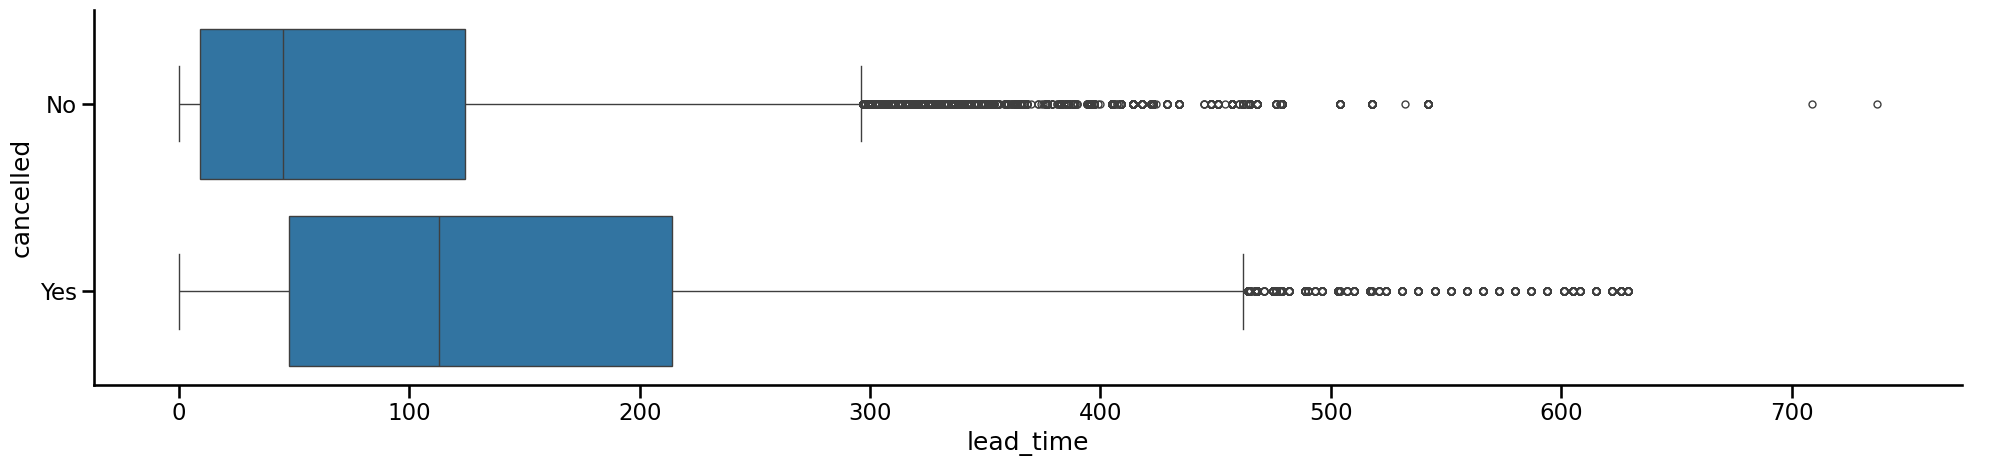

In [6]:
sns.catplot(data=hotel_data, kind='box', x='lead_time', y='cancelled', aspect=4);

The boxplot shows that lead_time does actually impact the probability of cancelling, people who cancelled their bookings booked them roughly twice as early as people who didn't cancel.

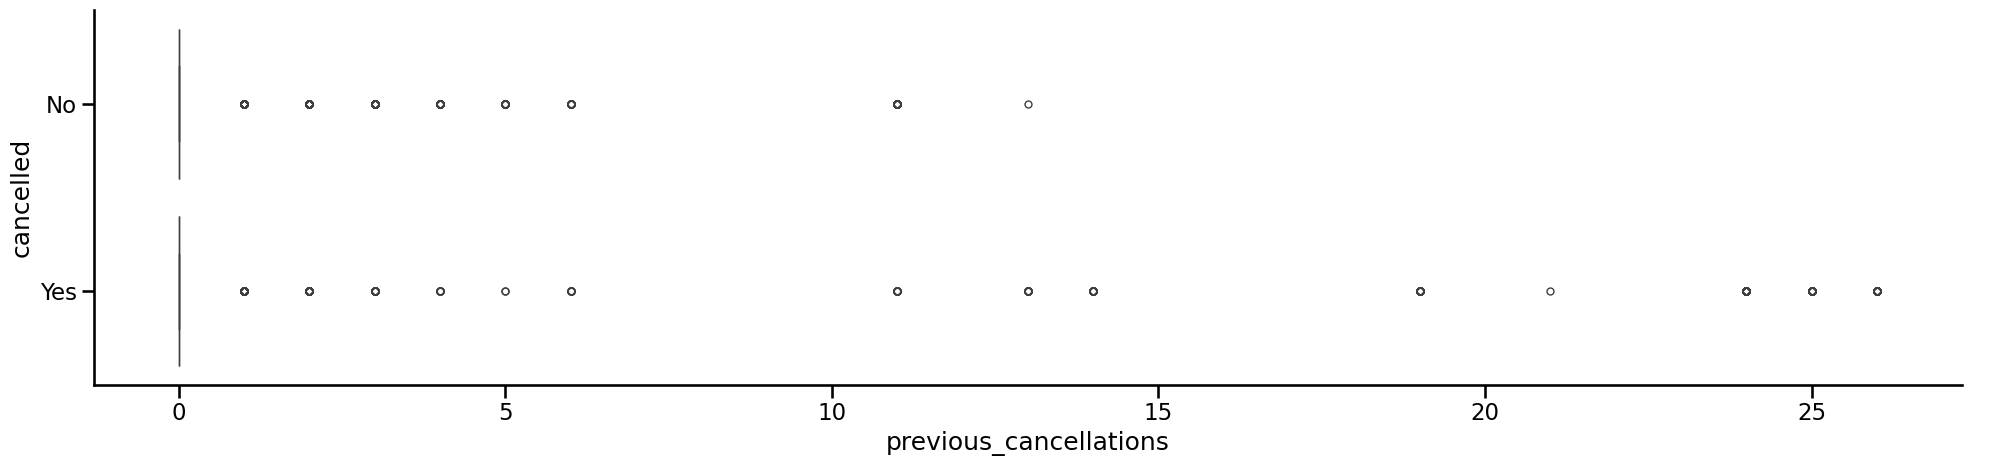

In [7]:
sns.catplot(data=hotel_data, kind='box', x='previous_cancellations', y='cancelled', aspect=4);

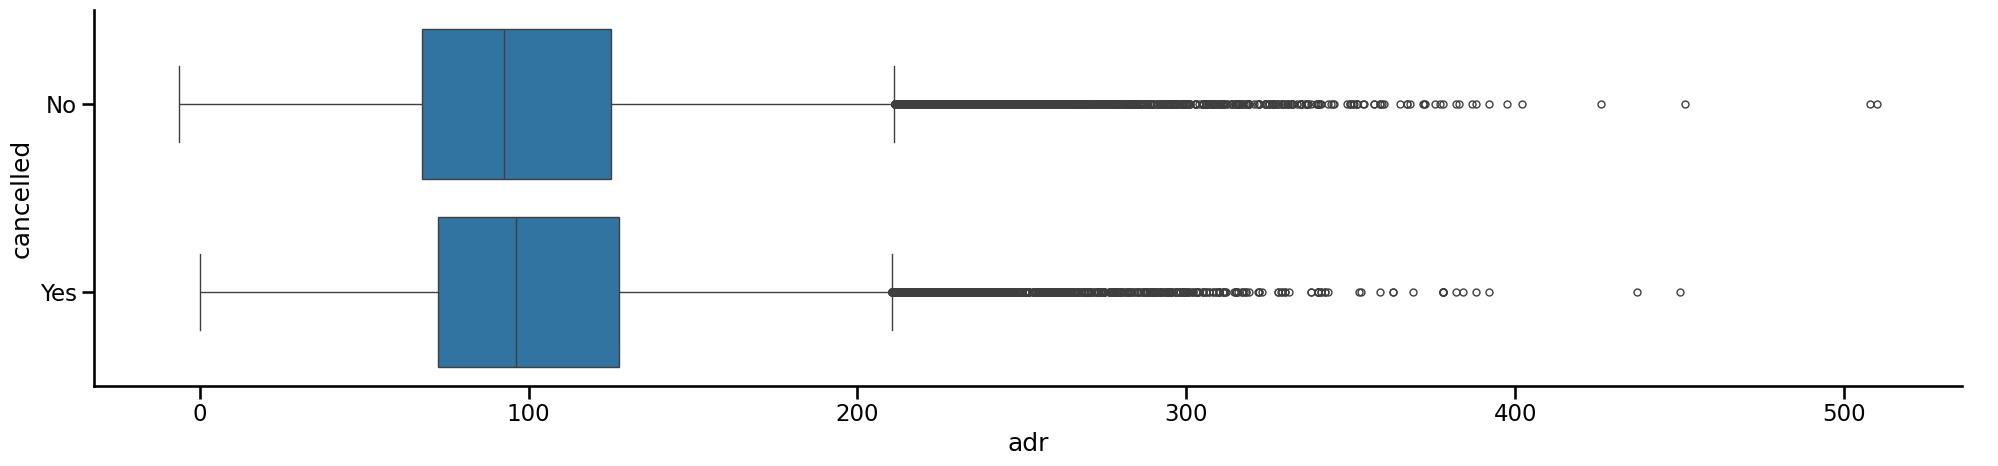

In [8]:
hotel_data = hotel_data[hotel_data['adr'] < 5000] # There was a single value at like 5500 which messed up the entire box plot
sns.catplot(data=hotel_data, kind='box', x='adr', y='cancelled', aspect=4);

The ADR is basically the same for both cancelled and not cancelled so it doesnt have any impact, I will explore the total cost too

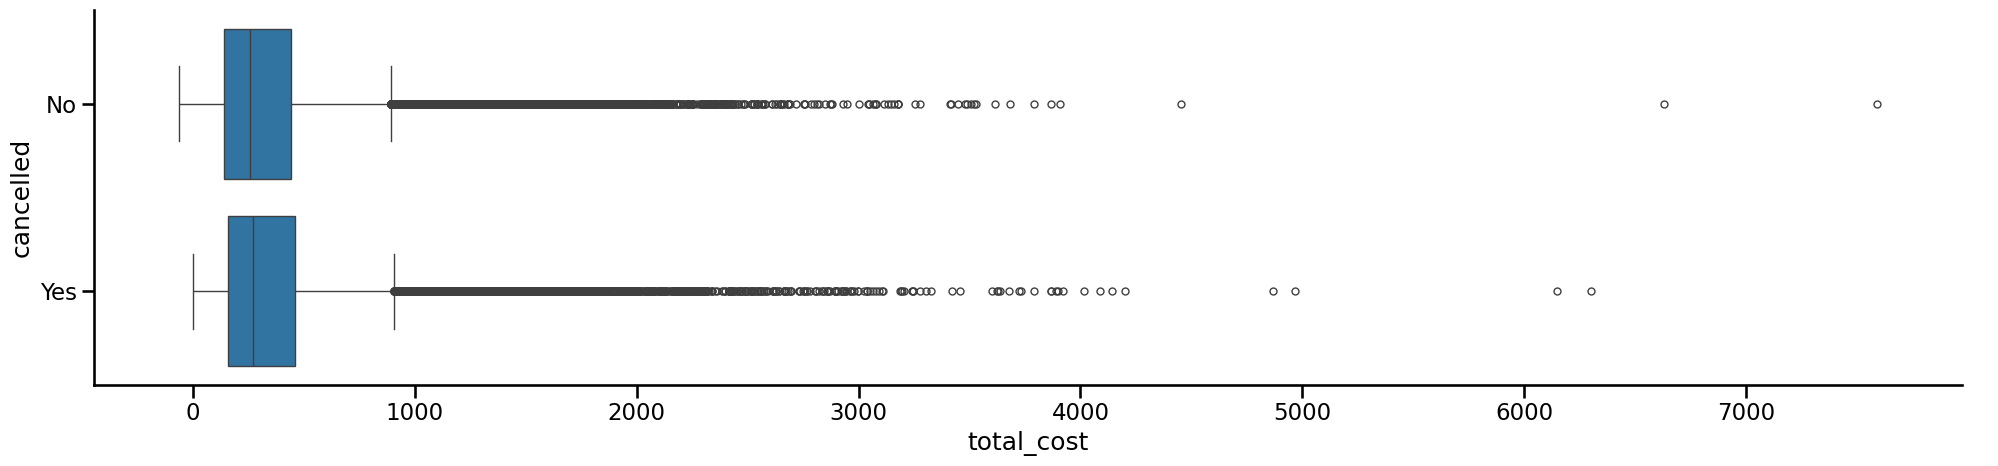

In [9]:
sns.catplot(data=hotel_data, kind='box', x='total_cost', y='cancelled', aspect=4);

Just like ADR total cost has no impact

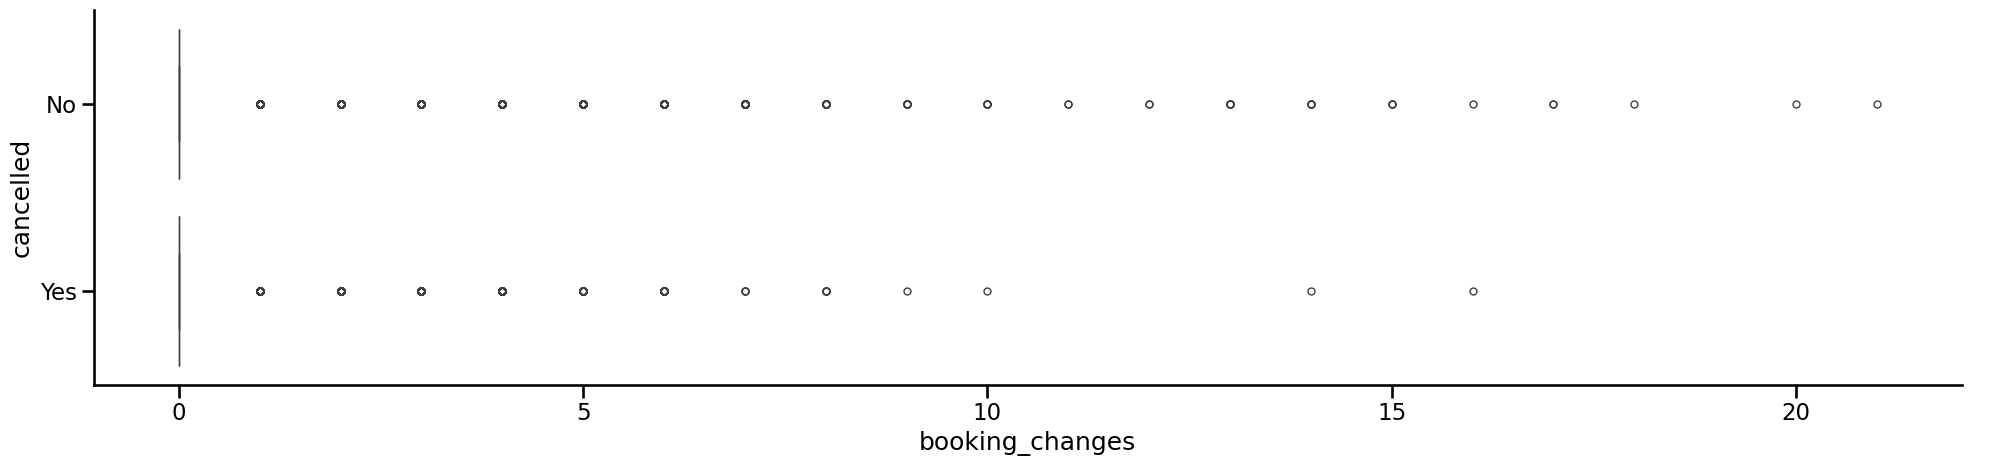

In [10]:
sns.catplot(data=hotel_data, kind='box', x='booking_changes', y='cancelled', aspect=4);

Booking changes has a very wide spread and most of the data points are at 0 which makes a box plot innefective for viewing the data

<Axes: xlabel='cancelled', ylabel='has_changes'>

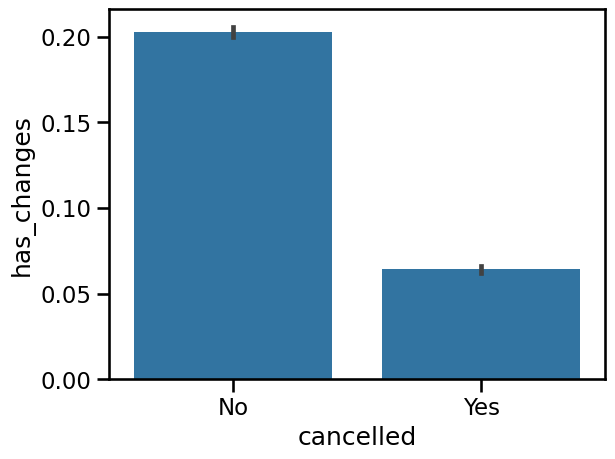

In [11]:
hotel_data = hotel_data.copy()
hotel_data['has_changes'] = hotel_data['booking_changes'] > 0
sns.barplot(data=hotel_data, x='cancelled', y='has_changes')

<Axes: xlabel='cancelled', ylabel='has_requests'>

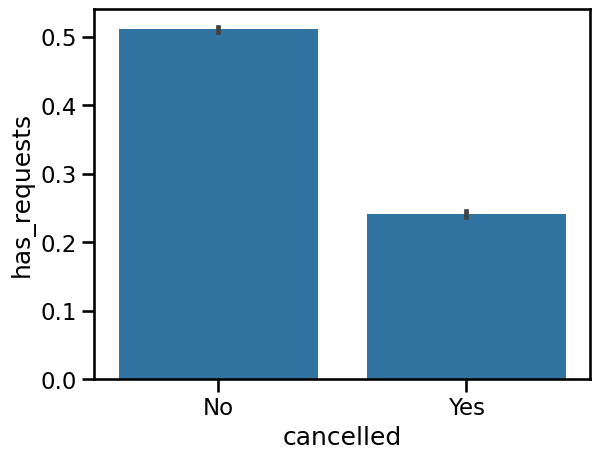

In [12]:
hotel_data = hotel_data.copy()
hotel_data['has_requests'] = hotel_data['total_of_special_requests'] > 0
sns.barplot(data=hotel_data, x='cancelled', y='has_requests')

we can see that the more changes and requests there is to a booking (which is equivalent to the effort put into it) the more likely the person is to keep theyre booking, however since most customers make no changes at all this isnt a reliable feature to base predictions on

<Axes: xlabel='cancelled', ylabel='been_waiting'>

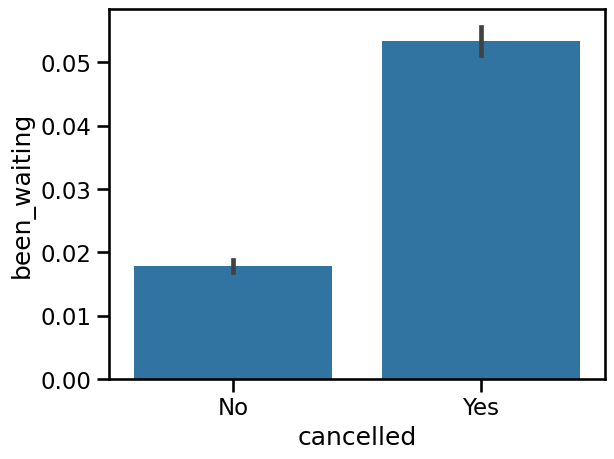

In [13]:
hotel_data = hotel_data.copy()
hotel_data['been_waiting'] = hotel_data['days_in_waiting_list'] > 0
sns.barplot(data=hotel_data, x='cancelled', y='been_waiting')

We also have to visualise days_in_waiting_list as a bar chart because again it has mostly values of 0, the barchart does confirm that the longer a customer has to wait the more likely it is they will cancel, there is probably a threshold of a couple days before they give up? I will explore this possibility in the slices section

## Exploring categorical features using `crosstab`

Use crosstabs on the categorical features to explore any differences between cancelled and non-cancelled bookings.

In [14]:
pd.crosstab(hotel_data['cancelled'], hotel_data['hotel'], normalize='columns') * 100

hotel,City Hotel,Resort Hotel
cancelled,,
No,58.273771,72.236645
Yes,41.726229,27.763355


The city hotel has a lot more cancellations than the resot hotel, maybe when using other features to predict cancellations, make the city hotel more sensitive to indicators

In [15]:
pd.crosstab(hotel_data['cancelled'], hotel_data['meal'], normalize='columns') * 100

meal,BB,FB,HB,SC,Undefined
cancelled,,,,,
No,62.61578,40.100251,65.539653,62.760563,75.534645
Yes,37.38422,59.899749,34.460347,37.239437,24.465355


Meals have no effect at all, uninportant

In [16]:
pd.crosstab(hotel_data['cancelled'], hotel_data['market_segment'], normalize='columns') * 100

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
cancelled,,,,,,,,
No,78.059072,86.944818,81.265345,84.658099,38.937964,65.686679,63.278857,0.0
Yes,21.940928,13.055182,18.734655,15.341901,61.062036,34.313321,36.721143,100.0


Market segment is important, group bookings have the highest cancelation rates at 61% which ranges from 2x to around 5x the rates of the other categories, maybe group bookings are less stable because you depend on other people, the other categories dont have much corelation, some are higher than others but overall stable, maybe hotels should make it easier for groups of people to enjoy and keep theyre bookings

In [17]:
pd.crosstab(hotel_data['cancelled'], hotel_data['repeated_guest'], normalize='columns') * 100

repeated_guest,No,Yes
cancelled,,
No,62.215454,85.511811
Yes,37.784546,14.488189


In [18]:
pd.crosstab(hotel_data['cancelled'], hotel_data['repeated_guest'])

repeated_guest,No,Yes
cancelled,,
No,71908,3258
Yes,43671,552


Repeated guests are an important feature, repeat guests cancel around half as much as non repeat guests, however a large majority of people are not repeat guests so we can't rely on this feature too much, but if a repeat guest appears it is unlikely they will cancel, the hotels can focus on keeping other groups of people hooked

## Exploring a slice
Create slices for different values of a categorical feature and explore these separately.

In [19]:
waiting_data = hotel_data[hotel_data['days_in_waiting_list'] > 0].copy()
waiting_data['days_in_waiting_list'].describe()

count    3698.000000
mean       74.938345
std        67.482918
min         1.000000
25%        38.000000
50%        56.000000
75%        91.000000
max       391.000000
Name: days_in_waiting_list, dtype: float64

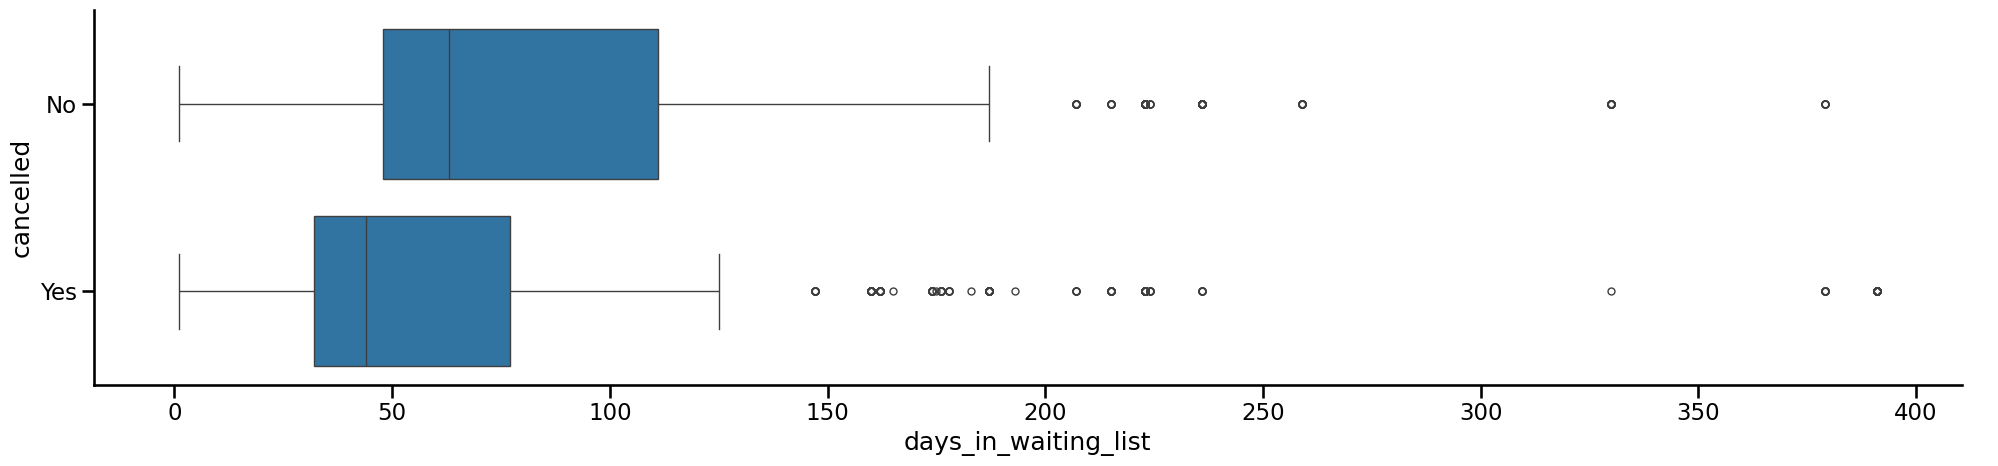

In [20]:
sns.catplot(data=waiting_data, kind='box', x='days_in_waiting_list', y='cancelled', aspect=4);

This is interesting, this box plot shows that people who waited longer actually didnt cancel? I will explore this further by creating bins of wait times

In [21]:
hotel_data = hotel_data.copy()

bins = [-1, 0, 14, 30, 60, 90, 400]
labels = ['0', '1-14 days', '15-30 days', '31-60 days', '61-90 days', '90+ days']
hotel_data['wait_categories'] = pd.cut(hotel_data['days_in_waiting_list'], bins=bins, labels=labels)

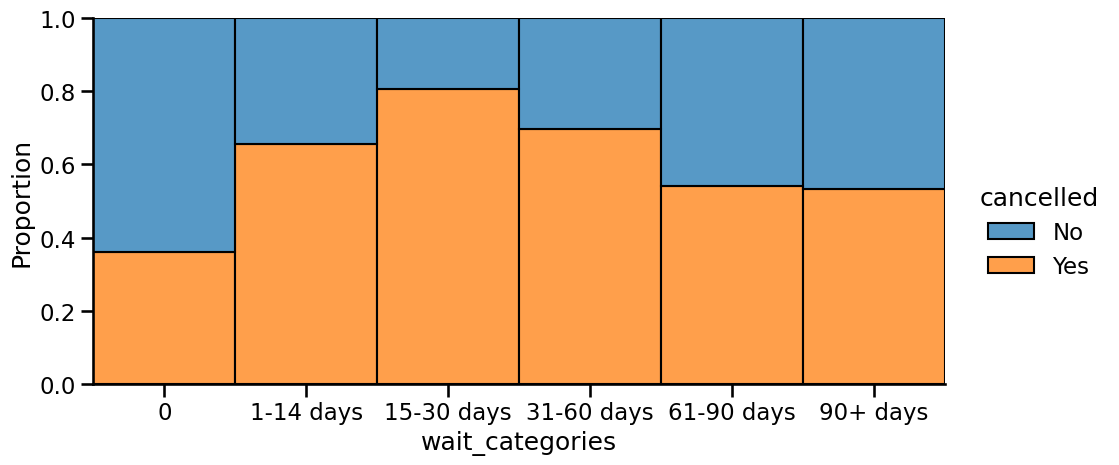

In [22]:
sns.displot(data=hotel_data, x='wait_categories', hue='cancelled', stat='proportion', multiple='fill', aspect=2);

days_in_waiting_list seems to be an unreliable feature, while it is true that more cancellations happen when the booker has to wait, the numbers are basically even when the wait time gets higher like over 2 months, but overall the hotel should try to minimize waiting time to keep more customers coming

In [23]:
# Slice data to view characteristics of each hotel, maybe some features are more important to one hotel than the other
city_data = hotel_data[hotel_data['hotel'] == 'City Hotel']
resort_data = hotel_data[hotel_data['hotel'] == 'Resort Hotel']

In [24]:
features=['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 
          'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 
           'total_of_special_requests', 'adr', 'total_guests', 'total_stay',	'total_cost']
          
# use group by to get the means of these for low and high income
city_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_guests,total_stay,total_cost
cancelled,,,,,,,,,,,,,,,
No,80.70,0.80,2.12,1.83,0.10,0.01,0.02,0.21,0.26,2.15,0.74,105.75,1.94,2.92,311.38
Yes,150.28,0.79,2.27,1.88,0.08,0.00,0.16,0.03,0.08,4.73,0.28,104.53,1.96,3.05,328.68


In [25]:
features=['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 
          'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 
           'total_of_special_requests', 'adr', 'total_guests', 'total_stay',	'total_cost']
          
# use group by to get the means of these for low and high income
resort_data.groupby('cancelled')[features].mean().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,adr,total_guests,total_stay,total_cost
cancelled,,,,,,,,,,,,,,,
No,78.84,1.13,3.01,1.83,0.11,0.02,0.01,0.19,0.34,0.69,0.67,90.79,1.95,4.14,400.92
Yes,128.68,1.34,3.44,1.96,0.19,0.01,0.35,0.02,0.15,0.09,0.49,105.79,2.15,4.78,525.28


The resort hotel shows a clear difference in ADR and total_cost between cancelled and not cancelled, the ADR is about 15 more for cancelled bookings, on the other hand the city hotel's ADR is useless, in conclusion the features based on price are important and should be used for predicting the resort hotels cancellations

Days in waiting list has a clear difference for the city hotel but not for the resort hotel, maybe I can explore days_in_waiting_list again but for the city_data slice

Both hotels actually have high rates of previous_cancellations cancelling again, I missed this earlier because the graph had mostly 0 values, the opposite is true for previous_bookings_not_cancelled

Both hotels show that a higher lead time is more likely to lead to cancellations, while the city hotel has a bigger jump, they both show a correlation which I have already explored

At the resort hotel the presence of children seems to make the booking less stable

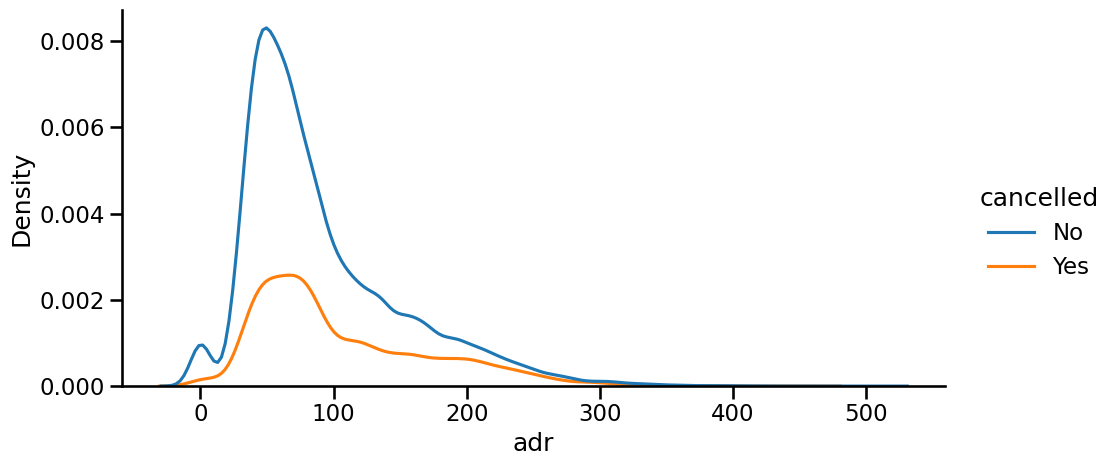

In [26]:
sns.displot(data=resort_data, x='adr', hue='cancelled', kind='kde', aspect=2)

/tmp/ipykernel_16/3562379152.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  resort_data['ADR_categories'] = pd.cut(resort_data['adr'], bins=bins, labels=labels)


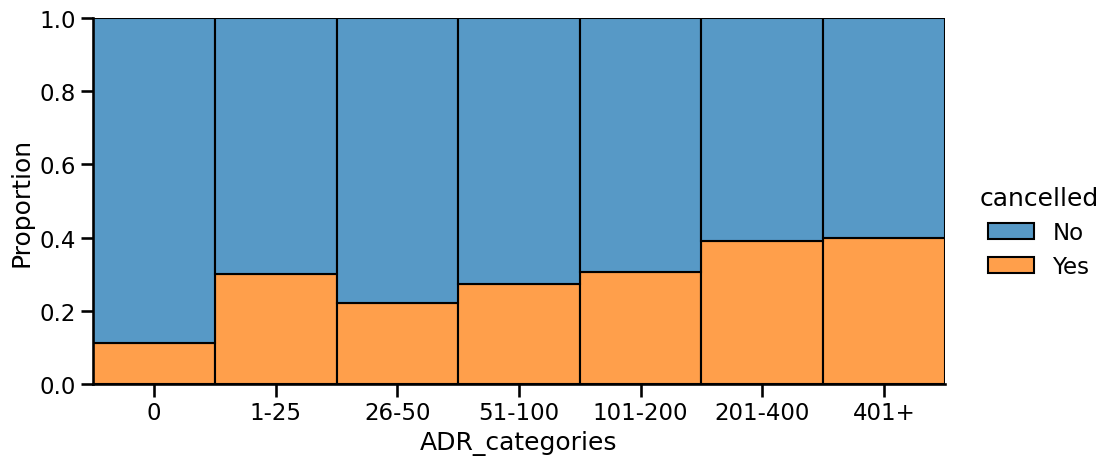

In [27]:
bins = [-1, 0, 25, 50, 100, 200, 400, 800]
labels = ['0', '1-25', '26-50', '51-100', '101-200', '201-400', '401+']
resort_data['ADR_categories'] = pd.cut(resort_data['adr'], bins=bins, labels=labels)

sns.displot(data=resort_data, x='ADR_categories', hue='cancelled', stat='proportion', multiple='fill', aspect=2);

This graph shows a steady increase in the amount of cancellations as ADR increases, with a slight outlier in the 1-25 category, ADR is important for the resort hotel

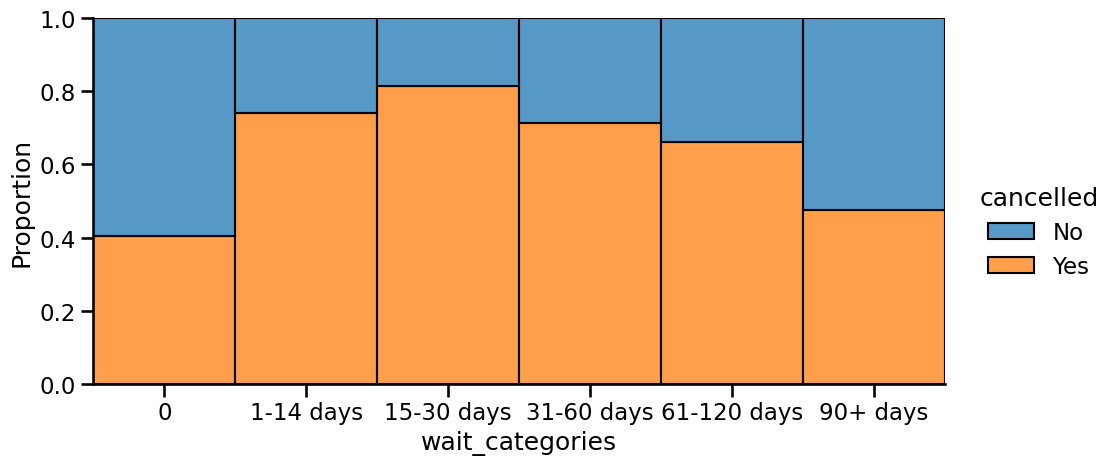

In [28]:
city_data = city_data.copy()

bins = [-1, 0, 14, 30, 60, 120, 400]
labels = ['0', '1-14 days', '15-30 days', '31-60 days', '61-120 days', '90+ days']
city_data['wait_categories'] = pd.cut(city_data['days_in_waiting_list'], bins=bins, labels=labels)

sns.displot(data=city_data, x='wait_categories', hue='cancelled', stat='proportion', multiple='fill', aspect=2);

This shows a more predictable relationship, it is non linear, it is a bell curve, as wait time increases more customers cancel their bookings, however there is an exception, when it reaches 1-2 months of waiting the customers are part of a new group of more dedicated individuals and they keep theyre booking despite waiting longer than other people, the critical time to stop customers from cancelling is between 15-30 days, after that it becomes less of a problem

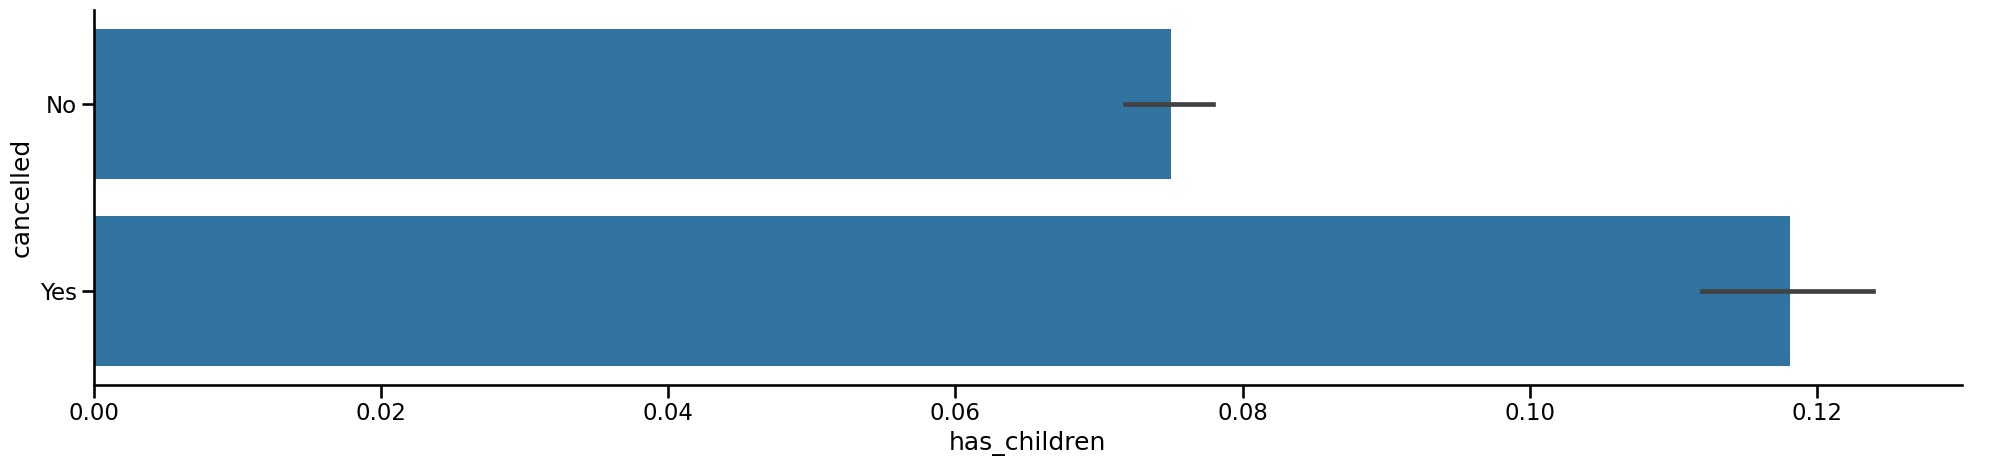

In [29]:
resort_data = resort_data.copy()
resort_data['has_children'] = resort_data['children'] > 0
sns.catplot(data=resort_data, kind='bar', x='has_children', y='cancelled', aspect=4);

Confirms that the resort hotel is more likely to be cancelled if the booker has children

# Observations

Likely to keep booking:
* Repeated guests
* People who make special requests or changes

Likely to cancel booking:
* Group bookings
* People who are in the waiting list
* People who book around more than 100 days in advance or very early in general

Hotel specific:

City:
* People who are in the waiting list for longer are more likely to canecel unless they pass the tipping point and are inside the dedicated subgroup after about 2 months of waiting

Resort:
* ADR affects cancellation higher ADR = more likely to cancel
* Having children in the booking also raises the probability of cancellations


Suggestions to hotel managers to lower cancellations

City manager:
* Dont allow cancellations of bookings made 100+ days in advance or probably better to make it non refundable
* Engage with the customers on the waiting list, send update emails, offers, etc to keep them hooked
* Spend less effort on repeated guests, encourage them to return and make it simpler for them, they are loyal, also make it harder for guests with a record of cancelling to book in the first place
* Speed up the waitlist, or prioritse customers who are in the dedicated subgroup, they intend to keep their bookings

Resort manager:
* Dont allow cancellations of bookings made 100+ days in advance or probably better to make it non refundable
* Engage with the customers on the waiting list, send update emails, offers, etc to keep them hooked
* Spend less effort on repeated guests, encourage them to return and make it simpler for them, they are loyal, also make it harder for guests with a record of cancelling to book in the first place
* Make it easier for families with children, offer kid meals, make more areas of the hotel accessible to all ages, simplify the process for families basically, maybe make family tickets or child tickets heavily discounted
* Price is a problem try to lower the higher prices and make them more consistent, alternatively make more expensive bookings worth it, include extra perks or free cool things for the bookers if they pay more, this way they feel that the price is worth it.